In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")

PROJECT_ROOT = Path.cwd().parent

RESULTS_DIR = PROJECT_ROOT / "results"

print("Libraries imported successfully!")

Libraries imported successfully!


In [10]:
result_files = {
    "Logistic Regression": "logistic_regression_metrics.csv",
    "Decision Tree": "decision_tree_metrics.csv",
    "KNN": "knn_metrics.csv",
    "Naive Bayes": "naive_bayes_metrics.csv",
    "SVM": "svm_metrics.csv"
}

model_results = []

for model_name, filename in result_files.items():

    file_path = RESULTS_DIR / filename

    df = pd.read_csv(file_path)

    model_results.append(df)

comparison_df = pd.concat(
    model_results,
    ignore_index=True
)

display(comparison_df)

,Model,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.802847,0.840267,0.661017,0.524194,0.584708,0.462990
1,Decision Tree,0.714591,0.649778,0.464198,0.505376,0.483912,0.287654
2,KNN,0.759431,0.771967,0.551205,0.491935,0.519886,0.361120
3,Naive Bayes,0.684698,0.806695,0.448773,0.836022,0.584038,0.411444
4,SVM,0.797865,0.783256,0.661765,0.483871,0.559006,0.440870


In [11]:
metric_columns = [
    "Accuracy",
    "AUC",
    "Precision",
    "Recall",
    "F1",
    "MCC"
]

display(
    comparison_df.style.format({
        col: "{:.4f}" for col in metric_columns
    }).highlight_max(
        subset=metric_columns,
        color="blue"
    )
)

,Model,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.8028,0.8403,0.6610,0.5242,0.5847,0.4630
1,Decision Tree,0.7146,0.6498,0.4642,0.5054,0.4839,0.2877
2,KNN,0.7594,0.7720,0.5512,0.4919,0.5199,0.3611
3,Naive Bayes,0.6847,0.8067,0.4488,0.8360,0.5840,0.4114
4,SVM,0.7979,0.7833,0.6618,0.4839,0.5590,0.4409


In [12]:
comparison_df.to_csv(
    RESULTS_DIR / "baseline_comparison.csv",
    index=False
)

print("Consolidated baseline results saved!")

Consolidated baseline results saved!


In [13]:
rankings = comparison_df[
    ["Model"] + metric_columns
].copy()

for metric in metric_columns:

    rankings[f"{metric}_Rank"] = (
        rankings[metric]
        .rank(ascending=False, method="min")
        .astype(int)
    )

display(
    rankings.sort_values("Accuracy_Rank")
)

,Model,Accuracy,AUC,Precision,Recall,F1,MCC,Accuracy_Rank,AUC_Rank,Precision_Rank,Recall_Rank,F1_Rank,MCC_Rank
0,Logistic Regression,0.802847,0.840267,0.661017,0.524194,0.584708,0.462990,1,1,2,2,1,1
4,SVM,0.797865,0.783256,0.661765,0.483871,0.559006,0.440870,2,3,1,5,3,2
2,KNN,0.759431,0.771967,0.551205,0.491935,0.519886,0.361120,3,4,3,4,4,4
1,Decision Tree,0.714591,0.649778,0.464198,0.505376,0.483912,0.287654,4,5,4,3,5,5
3,Naive Bayes,0.684698,0.806695,0.448773,0.836022,0.584038,0.411444,5,2,5,1,2,3


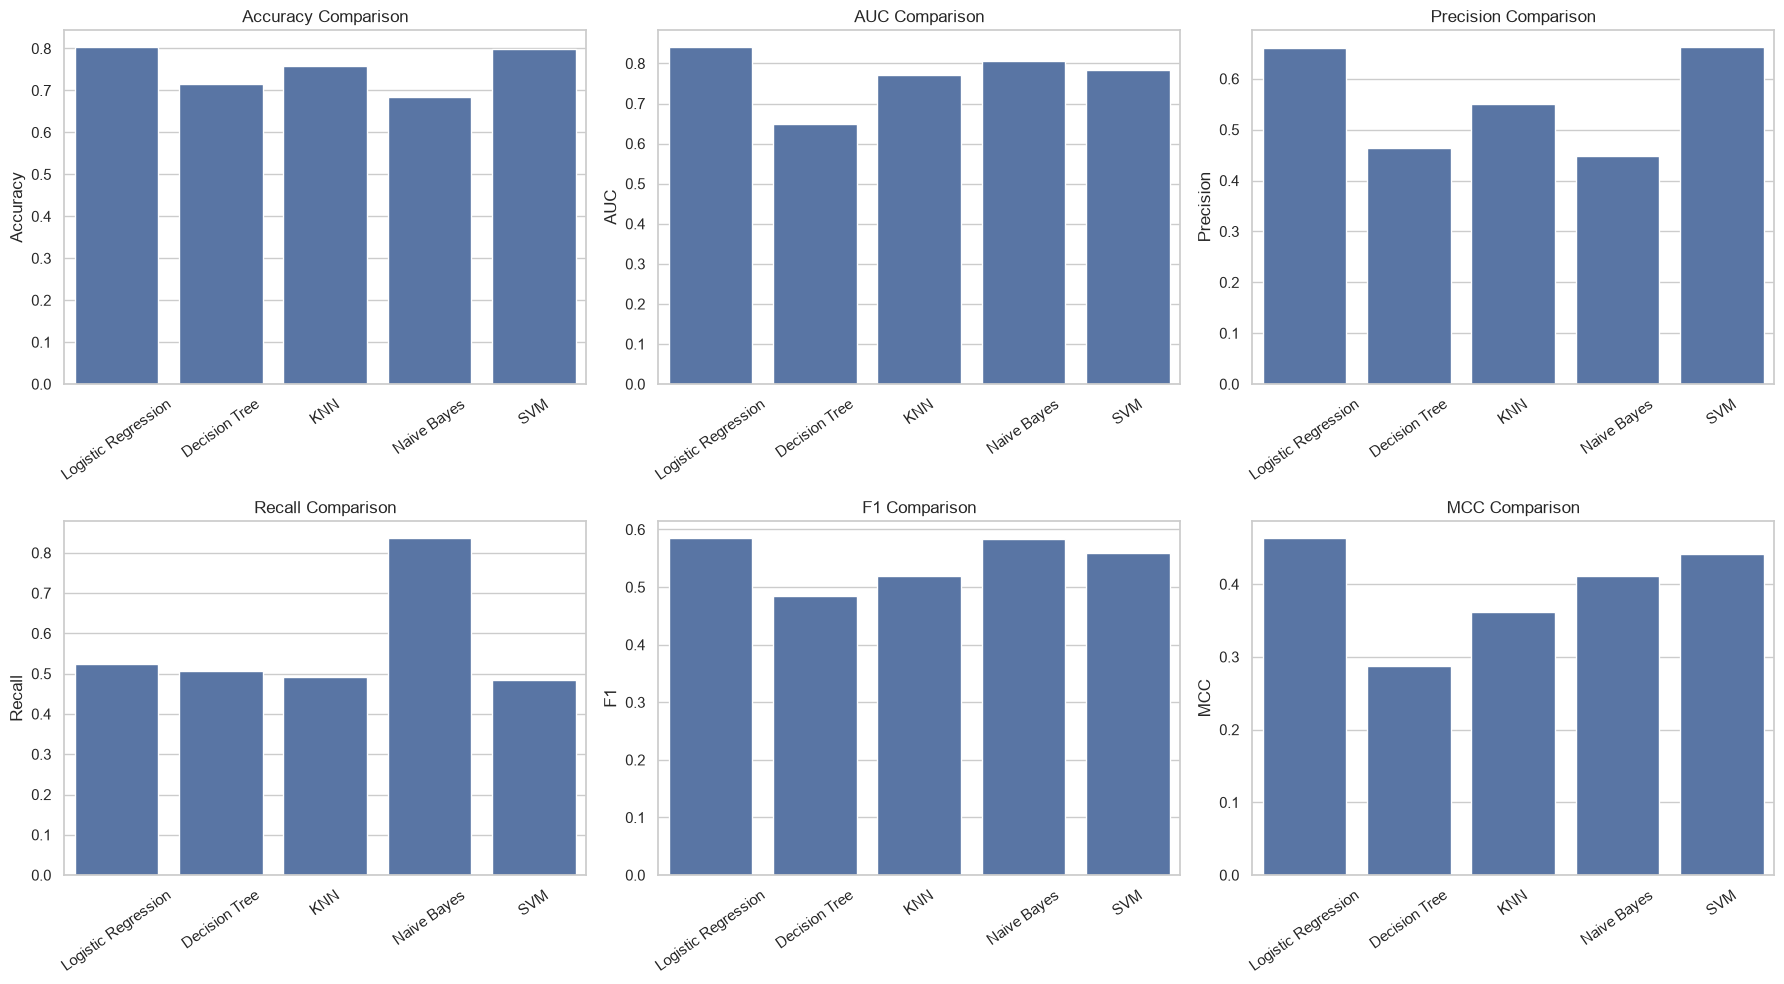

In [14]:
fig, axes = plt.subplots(
    2, 3,
    figsize=(18, 10)
)

for ax, metric in zip(axes.flatten(), metric_columns):

    sns.barplot(
        data=comparison_df,
        x="Model",
        y=metric,
        ax=ax
    )

    ax.set_title(f"{metric} Comparison")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()

In [15]:
best_model = comparison_df.loc[
    comparison_df["F1"].idxmax()
]

print("BEST BASELINE MODEL")
print("=" * 50)

print("Model:", best_model["Model"])

for metric in metric_columns:
    print(f"{metric}: {best_model[metric]:.4f}")

BEST BASELINE MODEL
Model: Logistic Regression
Accuracy: 0.8028
AUC: 0.8403
Precision: 0.6610
Recall: 0.5242
F1: 0.5847
MCC: 0.4630
